Run a simulation and sample genomes from the transmission network.

Sample at say 1%, 5%, and 10% of the transmissions (to begin with) and reconstruct the phylogeny.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict

import covasim as cv
from Bio import SeqIO
import networkx as nx
from scipy.stats import linregress, t as t_dist

from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf

from covasim.jhk_covasim4wastewater.intervention_search.simulation.runner import run_evo_simulation
from covasim.jhk_covasim4wastewater.intervention_search.analysis.mutation_tree import build_mutation_tree, build_infection_seq_tree, extract_sequenced_subtree, add_internal_leaves, mutation_tree_to_newick, export_fasta_from_G, set_all_branch_lengths_to_one
from covasim.jhk_covasim4wastewater.intervention_search.plotting.plot_mutation_tree import plot_mutation_tree, plot_erase_mutation_tree, plot_phylo_tree

from covasim.inference import Inference

Covasim 3.1.8 (2026-05-29) — © 2020-2026 by IDM


In [2]:
REF_FASTA     = '../sars-2-data/NC_045512_Hu-1.fasta'
FITNESS_CSV   = '../../../data/nt_fitness.csv'
ARTIC_PRIMERS = '../sars-2-data/ARTIC_V4-1.bed'
FIG_DIR = "../results"

ay4_fasta   = '../sars-2-data/variants/AY.4_consensus.fasta'
ba2_fasta   = '../sars-2-data/variants/BA.2.9_consensus.fasta'
xbb15_fasta = '../sars-2-data/variants/XBB.1.5.18_consensus.fasta'


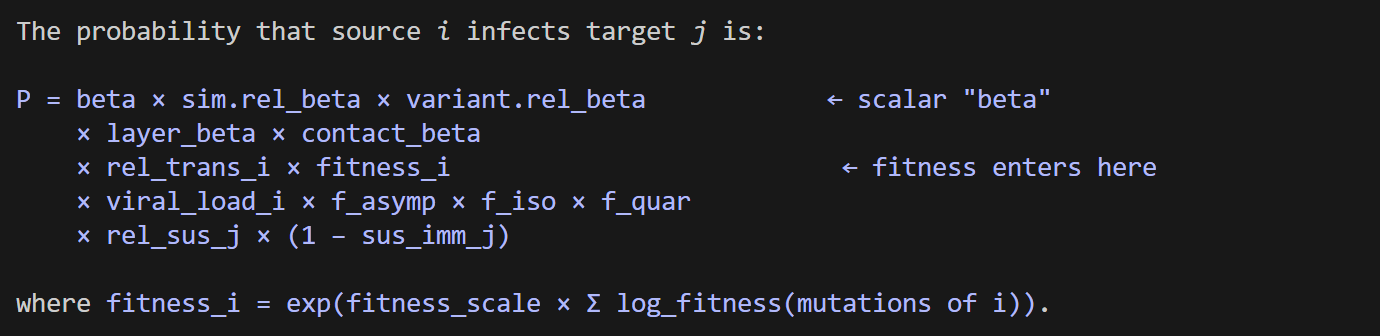

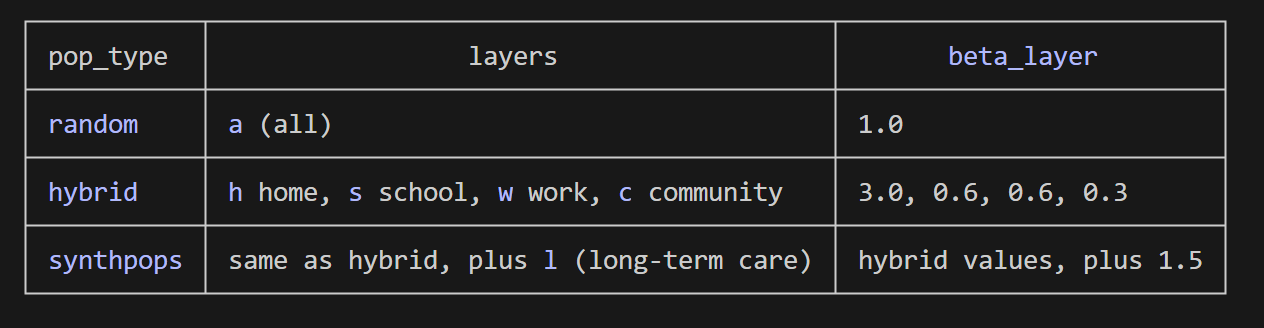

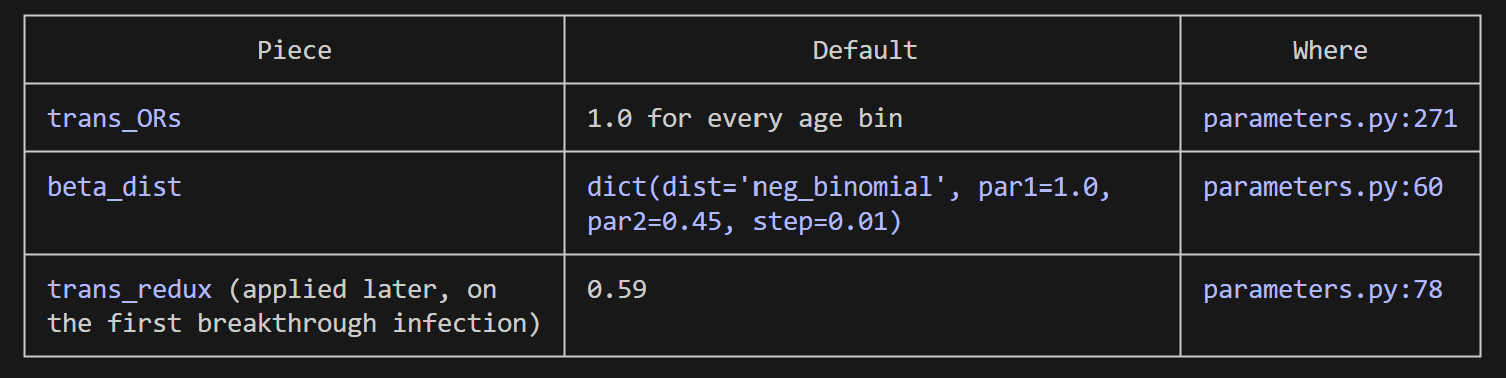

In [7]:
ay4 = cv.variant(
    variant        = {},
    label          = 'AY.4',
    days           = 30,
    n_imports      = 60,
    founding_fasta = ay4_fasta,
)
ba2 = cv.variant(
    variant        = {},
    label          = 'BA.2',
    days           = 70,
    n_imports      = 60,
    founding_fasta = ba2_fasta,
)
xbb15 = cv.variant(
    variant        = {},
    label          = 'XBB.1.5',
    days           = 30,
    n_imports      = 10,
    founding_fasta = xbb15_fasta,
)

sample_days = list(range(10, 61, 10))
# Routine clinical: 50 symptomatic agents per day, every 10 days.
cs_routine = cv.ClinicalSequencer(
    days      = sample_days,
    n_samples = 50,
    pool      = 'infectious', # no isolation or quarantine
    label     = 'CS_routine',
    # sequencing_batch_size defaults to 1, causing immediate release
)

In [8]:
def get_mutation_in_long_df_full_tree(mutation_nodes):
    rows = []
    for mutation_state, node in mutation_nodes.items():
        if not mutation_state:
            rows.append({"node": node, "mutation": None})
        for site, ref, alt in mutation_state:
            rows.append({"node": node, "mutation": cv.decode_sequence([ref])+str(int(site)+1)+cv.decode_sequence([alt])})
    df = pd.DataFrame(rows)
    df = df.dropna()
    return df

def get_mutation_in_long_df_inferred_tree(nodes_mutation):
    rows = []
    for node, mutation_state in nodes_mutation.items():
        if not mutation_state:
            rows.append({"node": node, "mutation": None})
        for site, ref, alt in mutation_state:
            rows.append({"node": node, "mutation": ref+str(site)+alt}) # this is already 1-based idx
    df = pd.DataFrame(rows)
    df = df.dropna()
    return df

def plot_mut_occurrence(df):
    mutation_counts = df["mutation"].value_counts()  # counts per individual mutation in full transmission tree
    n_dist = mutation_counts.value_counts().sort_index()  # index = n, values = number of mutations occurring n times

    _, ax = plt.subplots(figsize=(7, 5))
    ax.scatter(n_dist.index, n_dist.values, color="#2a78d6", s=80, zorder=3)
    
    ax.set_xlabel("Number of occurrences (n)")
    ax.set_ylabel("Number of mutations")
    ax.set_title("Distribution of mutation occurrence counts")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.xaxis.get_major_locator().set_params(integer=True)
    ax.yaxis.get_major_locator().set_params(integer=True)
    ax.set_xlim(0, n_dist.index.max() + 1)
    ax.set_ylim(0, n_dist.values.max() + 2)
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    
    plt.tight_layout()
    plt.show()

def get_fitness():
    fitness = pd.read_csv(FITNESS_CSV)
    ref = SeqIO.read(REF_FASTA, format="fasta")
    def get_ref_nt(nt_site):
        return str(ref.seq)[nt_site-1]
    fitness["ref"] = fitness["nt_site"].apply(lambda x: get_ref_nt(x))
    assert (fitness.loc[(fitness["ref"] == fitness["nt"]) & (fitness["nt_differs_among_clade_founders"] == False), "fitness"] == 0).all()

    # some variant with ref == alt has non-zero fitness value, drop them here
    fitness = fitness[fitness["nt"] != fitness["ref"]]
    fitness["mutation"] = fitness["ref"] + fitness["nt_site"].astype(str) + fitness["nt"]
    fitness_mapping = dict(zip(fitness["mutation"], fitness["fitness"]))
    return fitness_mapping

def compute_node_stats(h_tree, mutation_nodes, node_events):
    fitness_mapping = get_fitness()
    rows = []
    for mutation_state, node in mutation_nodes.items():
        if not mutation_state:
            rows.append({"node": node, "mutation": None})
        for site, ref, alt in mutation_state:
            rows.append({"node": node, "mutation": cv.decode_sequence([ref])+str(int(site)+1)+cv.decode_sequence([alt])})
    df = pd.DataFrame(rows)
    df = df.dropna()

    # calculate the sum of fitness value for each node (mutation state)
    df["fitness"] = df["mutation"].map(fitness_mapping).fillna(0)
    stats = df.groupby("node", as_index=False)["fitness"].sum()

    internal_nodes = [n for n in h_tree.nodes if h_tree.out_degree(n) > 0]
    n_descendants = {n: len(nx.descendants(h_tree, n)) for n in internal_nodes} # exclude the tips - they have no descdents

    earliest_infection_day = {node: min(int(e.rsplit("_", 1)[1]) for e in events) for node, events in node_events.items() if events}
    n_infection_times = {node: len(events) for node, events in node_events.items() if events}

    stats["n_descendants"] = stats["node"].map(n_descendants)
    stats["earliest_infection_day"] = stats["node"].map(earliest_infection_day)
    stats["n_infection_times"] = stats["node"].map(n_infection_times)
    stats = stats.dropna(subset=["fitness", "n_descendants"])

    # rm the node which was reinfected too many times
    # stats = stats[stats["n_infection_times"] <= 30]
    return stats

def plot_rt(sim):
    r = sim.compute_r_eff(method='daily', smoothing=0)
    _, ax = plt.subplots(figsize=(8, 4))
    ax.plot(range(len(r)), r, marker="o")
    ax.set_xlabel("day")
    ax.set_ylabel("Rt from sim")
    ax.set_title("Rt per day")
    plt.show()

In [9]:
def plot_ndesc_vs_fitness(node_stats):
        _, ax = plt.subplots(figsize=(7, 5))
        x = node_stats["fitness"].to_numpy(dtype=float)
        y = node_stats["n_descendants"].to_numpy(dtype=float)

        ax.scatter(x, y, color="#2a78d6", s=80, alpha=0.5, zorder=3)

        # regression line (least squares) with 95% CI of the fit
        res = linregress(x, y)
        xs = np.linspace(x.min(), x.max(), 200)
        yhat = res.slope * xs + res.intercept

        n = len(x)
        resid = y - (res.slope * x + res.intercept)
        s_err = np.sqrt(np.sum(resid**2) / (n - 2))
        t = t_dist.ppf(0.975, n - 2)
        ci = t * s_err * np.sqrt(1 / n + (xs - x.mean())**2 / np.sum((x - x.mean())**2))

        ax.fill_between(xs, yhat - ci, yhat + ci, color="#d62728", alpha=0.4, lw=0, zorder=2,
                        label="95% CI")
        ax.plot(xs, yhat, color="#d62728", lw=2, zorder=4,
                label=f"y = {res.slope:.2f}x + {res.intercept:.2f}")
        ax.legend(frameon=False)

        ax.set_xlabel("sample-level fitness score")
        ax.set_ylabel("n_descendants")
        ax.set_title("Sim with fitness model")

        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        ax.set_xlim(x.min() - 1, x.max() + 1)
        ax.set_ylim(y.min() - 1, y.max() + 1)
        ax.grid(axis="y", linestyle="--", alpha=0.4)

        plt.tight_layout()
        plt.show()

In [10]:
evo_pars = dict(
    enable            = True,
    reference         = REF_FASTA,
    mol_clock_rate    = 1e-5, # ~1 substitution/genome/month at 30 000 nt = 26/29903/12
    sub_model         = 'JC', # decides which mutations happen
    fitness_model = "bloom_nt", # controls transmission rate
    fitness_data_path = FITNESS_CSV,
    store_infection_log=True,
    fitness_scale     = 0.8, 
    # bottleneck        = False,
    # rejection_prob=0.9,
)
sim_pars = dict(
    pop_size=1000,
    pop_type='random',
    pop_infected=10,
    start_day='2021-01-01', 
    n_days=61,
    rand_seed=1,
    verbose=0,    
    variants=[], 
    beta=0.016,
    analyzers=[cs_routine],    
    viral_dist   = dict(
        frac_time=0.3, 
        load_ratio=1, # how much more infectious the early phase is than the late phase, flat 
        high_cap=4
    ), 
    beta_dist = dict(dist='neg_binomial', par1=1.0, par2=1000, step=0.01),
    asymp_factor = 1.0, # all infectious agents transmit equally
    iso_factor   = dict(a=1.0), # isolated or quarantined agents are treated the same as everyone, does not affect sim here since no isolation or qurantine in infectious pool
    quar_factor  = dict(a=1.0),
    # rel_symp_prob   = 0.0, # everyone asymptomatic. status of disease: asymptomatic or mild (about 8 days), severe (18+ days), or death
    # rel_severe_prob = 0.0, # no one becomes severe, and therefore no one becomes critical or dies
    use_waning      = False, # true gives recovered agents partial immunity
    trans_redux     = 1.0, # Breakthrough reduction: on a first breakthrough infection, rel_trans is multiplied by trans_redux
)


sim = cv.Sim(pars=sim_pars, evo_pars=evo_pars)
sim.initialize()
# sim.people.rel_trans[:] = 1.0 # how infectious this agent is when they are infected
sim.people.rel_sus[:]   = 1.0 # how easily this agent will be infected
sim.run()

cs_routine = sim.get_analyzer('CS_routine')

/home/eleanor124/projects/covasim4wastewater/covasim/clinical.py:194: UserWarning: ClinicalSequencer day 10: requested 50 samples but only 20 agents are available in pool='infectious'. Returning all 20 agents.
  warnings.warn(
/home/eleanor124/projects/covasim4wastewater/covasim/clinical.py:194: UserWarning: ClinicalSequencer day 20: requested 50 samples but only 29 agents are available in pool='infectious'. Returning all 29 agents.
  warnings.warn(
/home/eleanor124/projects/covasim4wastewater/covasim/clinical.py:194: UserWarning: ClinicalSequencer day 30: requested 50 samples but only 17 agents are available in pool='infectious'. Returning all 17 agents.
  warnings.warn(
/home/eleanor124/projects/covasim4wastewater/covasim/clinical.py:194: UserWarning: ClinicalSequencer day 40: requested 50 samples but only 40 agents are available in pool='infectious'. Returning all 40 agents.
  warnings.warn(


Policy B mutation tree: nodes=1000, edges=999


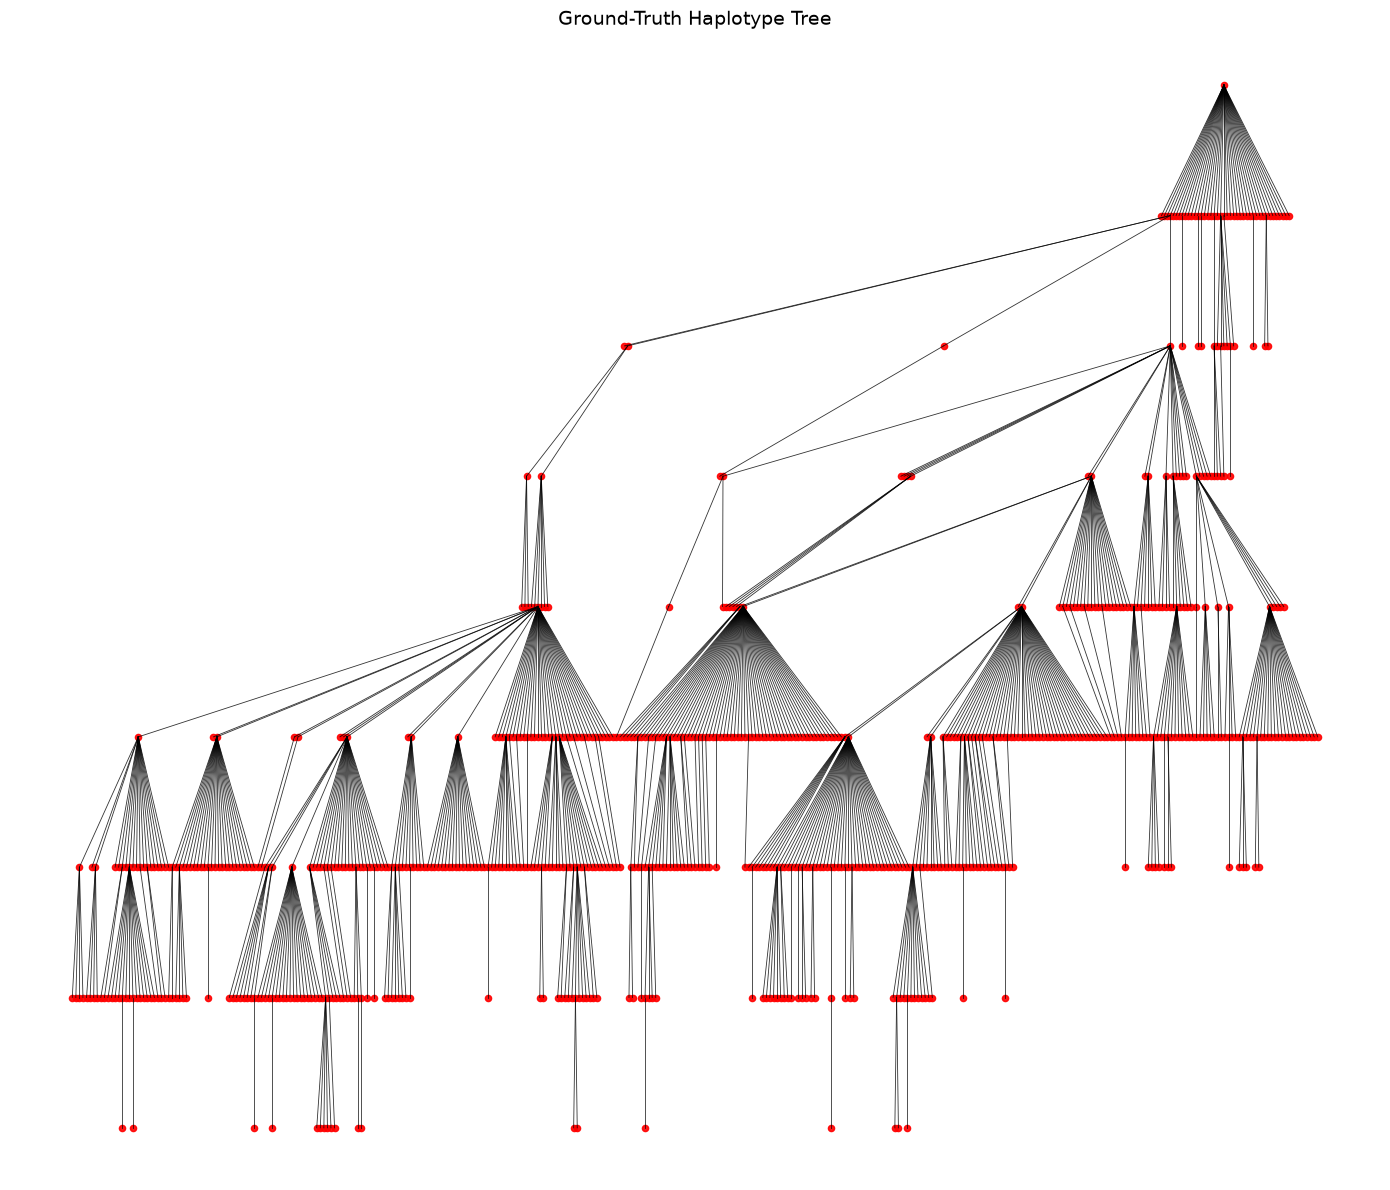

In [11]:
G = build_mutation_tree(sim) # event-base tt
print(f"Policy B mutation tree: nodes={len(G.nodes)}, edges={len(G.edges)}")

H, mutation_nodes, node_events = build_infection_seq_tree(sim) # halpotype-based
plot_mutation_tree(H, title="Ground-Truth Haplotype Tree")

In [ ]:
plot_rt(sim)

In [ ]:
print(f"pop_size (actual agents):     {sim['pop_size']}")
print(f"pop_scale:                    {sim['pop_scale']}")
print(f"scaled_pop_size:              {sim.scaled_pop_size}")
print(f"rescale:                      {sim['rescale']}")

# current scale factor at end of sim
print(f"final scale factor:           {sim.rescale_vec[-1]:.1f}")

log    = sim.people.infection_log
n_muts = [e['n_mutations'] for e in log if 'n_mutations' in e]

print(f'Transmission events:    {len(log):,}')
print(f'Mean branch mutations:  {np.mean(n_muts):.3f}')
print(f'Max branch mutations:   {max(n_muts)}')

fitness value vs freq in simulation

In [ ]:
node_stats = compute_node_stats(H, mutation_nodes, node_events)
plot_ndesc_vs_fitness(node_stats)

In [ ]:
df_mut_full_tree = get_mutation_in_long_df_full_tree(mutation_nodes) # make this unique mut??
plot_mut_occurrence(df_mut_full_tree)

In [ ]:
df_mut_full_tree["mutation"].value_counts()

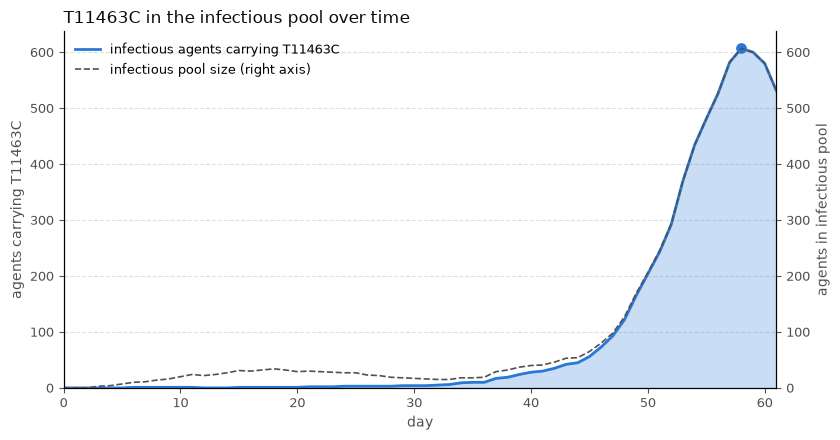

most prevalent mutation: T11463C   peak 100.00% on day 53


In [26]:
def agent_mutations_from_log(sim):
    '''Cumulative mutations carried by each agent, read from the infection log.

    Each log entry gives the mutations that arose on that transmission (branch_mutations);
    an agent carries those plus everything its source already carried. The log is in
    chronological order, so a source's state is always known before its targets' are needed.

    Args:
        sim (Sim): the finished sim

    Returns:
        dict agent index -> frozenset of (site, from_nt, to_nt)
    '''
    carried = {}
    for entry in sim.people.infection_log:
        source = entry["source"]
        parent = frozenset() if source is None else carried.get(source, frozenset())
        carried[entry["target"]] = parent | set(entry.get("branch_mutations", []))
    return carried


def infection_windows(sim, pool='infectious'):
    '''First and last day each agent is in the pool, as two arrays indexed by agent.

    The window runs from date_infectious (or date_exposed for pool='infected') up to but
    not including date_recovered. Death ends it early; an agent who has neither recovered
    nor died by the end stays in the pool to the last day. This matches agents_on_day() in
    reconstruct_phylogeny.ipynb and ClinicalSequencer's pool='infectious'.

    Args:
        sim (Sim):  the finished sim
        pool (str): 'infectious' (default), or 'infected' to also count latent agents

    Returns:
        (first_day, last_day) float arrays; first_day is nan for agents never infected
    '''
    people = sim.people
    start  = people.date_infectious if pool == 'infectious' else people.date_exposed
    start  = np.asarray(start, dtype=float)
    end    = np.asarray(people.date_recovered, dtype=float)
    dead   = np.asarray(people.date_dead, dtype=float)
    end    = np.where(np.isfinite(end), end, np.where(np.isfinite(dead), dead, np.inf))
    return start, end


def infectious_on_day(sim, day, pool='infectious'):
    '''Set of agents in the pool on one day.'''
    start, end = infection_windows(sim, pool=pool)
    return set(np.flatnonzero(np.isfinite(start) & (start <= day) & (end > day)).tolist())


def pool_size_over_time(sim, pool='infectious'):
    '''Number of agents in the pool on each day, as an array indexed by day.'''
    start, end = infection_windows(sim, pool=pool)
    days = np.arange(sim['n_days'] + 1)
    return np.array([np.sum(np.isfinite(start) & (start <= d) & (end > d)) for d in days])


def mutation_carriers_over_time(sim, pool='infectious'):
    '''Number of agents in the pool carrying each mutation, per day.

    An agent counts on every day they are in the pool, not only on the day they were infected.

    Args:
        sim (Sim):  the finished sim
        pool (str): 'infectious' (default) or 'infected', passed to infection_windows()

    Returns:
        DataFrame indexed by day, one column per mutation, values are agent counts
    '''
    n_days     = sim['n_days']
    carried    = agent_mutations_from_log(sim)
    start, end = infection_windows(sim, pool=pool)

    tally = defaultdict(lambda: np.zeros(n_days + 1))
    for agent, mutations in carried.items():
        if not np.isfinite(start[agent]):
            continue
        first = max(0, int(np.ceil(start[agent])))
        last  = min(n_days, int(np.ceil(end[agent])) - 1)
        if last < first:
            continue
        for site, ref, alt in mutations:
            label = cv.decode_sequence([ref]) + str(int(site) + 1) + cv.decode_sequence([alt])
            tally[label][first:last + 1] += 1
    return pd.DataFrame(dict(tally), index=range(n_days + 1))


def mutation_prevalence_over_time(sim, n_top=10, pool='infectious'):
    '''Prevalence of each mutation per day, within the infectious pool.

    Prevalence on day d is the number of agents in the pool on day d whose genome carries
    the mutation, divided by the number of agents in the pool on day d. Days with an empty
    pool are NaN.

    Args:
        sim (Sim):   the finished sim
        n_top (int): how many mutations to keep; None keeps all of them
        pool (str):  'infectious' (default) or 'infected', passed to infection_windows()

    Returns:
        DataFrame indexed by day, one column per mutation, values in 0-1, most prevalent first
    '''
    counts    = mutation_carriers_over_time(sim, pool=pool)
    pool_size = pool_size_over_time(sim, pool=pool).astype(float)
    pool_size[pool_size == 0] = np.nan                       # no pool, no prevalence
    prev  = counts.div(pool_size, axis=0)
    order = prev.max().sort_values(ascending=False).index   # rank by peak prevalence
    if n_top is not None:
        order = order[:n_top]
    return prev[order]


def plot_mutation_prevalence(sim, mutation=None, ax=None, show_pool=True, pool='infectious'):
    '''Plot how many agents in the infectious pool carry one mutation, over time.

    Left axis: agents in the pool carrying the mutation. Right axis: agents in the pool.
    Both axes share one scale, so the gap between the two curves is the agents in the pool
    without the mutation. The mutation with the highest peak prevalence is chosen unless
    one is named.

    Args:
        sim (Sim):         the finished sim
        mutation (str):    plot this mutation instead of the most prevalent one
        ax (axes):         existing axes to draw on; a new figure is made if None
        show_pool (bool):  also draw the pool size on the right axis
        pool (str):        'infectious' (default) or 'infected'

    Returns:
        (ax, mutation, series) -- the mutation drawn and its daily prevalence (share of pool)
    '''
    prev = mutation_prevalence_over_time(sim, n_top=None, pool=pool)
    if mutation is None:
        mutation = prev.columns[0]
    series    = prev[mutation]
    carriers  = mutation_carriers_over_time(sim, pool=pool)[mutation]
    pool_size = pool_size_over_time(sim, pool=pool)
    days      = np.arange(sim['n_days'] + 1)

    if ax is None:
        _, ax = plt.subplots(figsize=(8.5, 4.5))

    ax.fill_between(days, carriers.values, color="#2a78d6", alpha=0.25, zorder=3)
    ax.plot(days, carriers.values, color="#2a78d6", lw=2.0, zorder=4,
            label=f"{pool} agents carrying {mutation}")

    top = max(1, pool_size.max()) * 1.05
    ax.set_ylim(0, top)
    if show_pool:
        ax2 = ax.twinx()
        ax2.plot(days, pool_size, color="#52514e", lw=1.2, ls="--", zorder=2)
        ax2.set_ylim(0, top)                                   # same scale as the left axis
        ax2.set_ylabel(f"agents in {pool} pool", fontsize=10, color="#52514e")
        ax2.tick_params(labelsize=9, colors="#52514e")
        ax2.spines["top"].set_visible(False)
        ax.plot([], [], color="#52514e", lw=1.2, ls="--", label=f"{pool} pool size (right axis)")

    peak_day = int(carriers.idxmax())
    ax.scatter([peak_day], [carriers.max()], s=45, color="#2a78d6", zorder=5)
    # ax.annotate(f"peak {int(carriers.max())} of {pool_size[peak_day]} on day {peak_day}",
    #             xy=(peak_day, carriers.max()), xytext=(-8, 0), textcoords="offset points",
    #             ha="right", va="center", fontsize=9, color="#0b0b0b")

    ax.set_xlim(0, sim['n_days'])
    ax.xaxis.get_major_locator().set_params(integer=True)
    ax.yaxis.get_major_locator().set_params(integer=True)
    ax.spines["top"].set_visible(False)
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    ax.tick_params(labelsize=9, colors="#52514e")
    ax.set_xlabel("day", fontsize=10, color="#52514e")
    ax.set_ylabel(f"agents carrying {mutation}", fontsize=10, color="#52514e")
    ax.set_title(f"{mutation} in the {pool} pool over time", fontsize=12,
                 color="#0b0b0b", loc="left")
    ax.legend(frameon=False, fontsize=9, loc="upper left")
    return ax, mutation, series


ax, mutation, series = plot_mutation_prevalence(sim)
plt.tight_layout()
plt.show()

print(f"most prevalent mutation: {mutation}   peak {series.max():.2%} on day {int(series.idxmax())}")

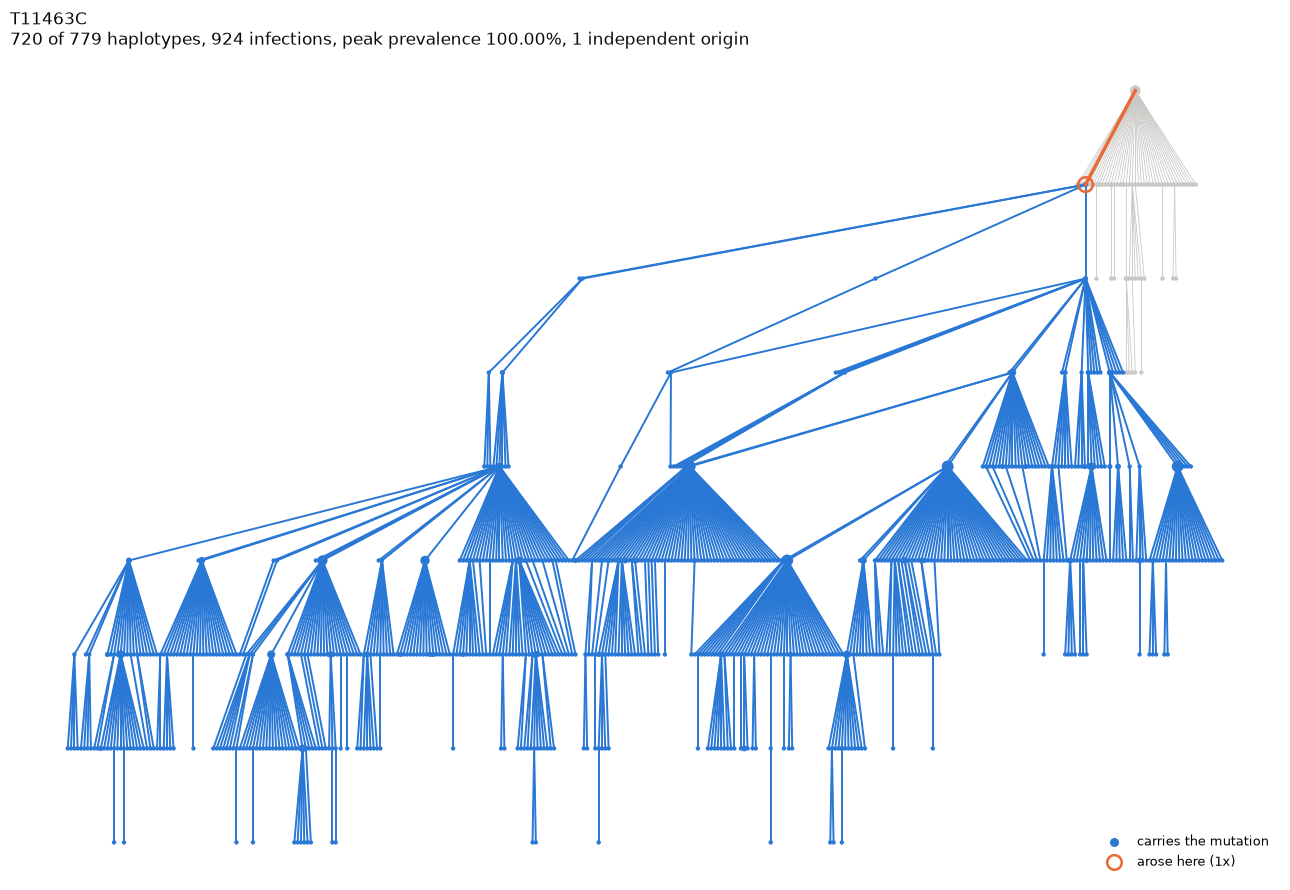

In [13]:
from networkx.drawing.nx_agraph import graphviz_layout


def mutation_label(site, ref, alt):
    '''Label a mutation tuple the way the long mutation tables do, 1-based.'''
    return cv.decode_sequence([ref]) + str(int(site) + 1) + cv.decode_sequence([alt])


def mutation_carriers(G):
    '''Haplotypes carrying each mutation, in one pass over the tree.

    A haplotype's mutation set is cumulative, so every descendant of the node where a
    mutation arose also carries it -- the carrier set is a whole clade, not one node.

    Args:
        G (DiGraph): haplotype tree from build_infection_seq_tree()

    Returns:
        dict mutation label -> frozenset of node ids
    '''
    carriers = defaultdict(set)
    for node in G.nodes:
        for mutation in G.nodes[node].get("mutations", ()):
            carriers[mutation_label(*mutation)].add(node)
    return {mutation: frozenset(nodes) for mutation, nodes in carriers.items()}


def mutation_origins(G, carriers):
    '''Edges on which a mutation arose: the child carries it, the parent does not.'''
    return [(u, v) for u, v in G.edges if v in carriers and u not in carriers]


def plot_mutation_on_tree(G, mutation, node_events=None, peak=None, size_by_agents=True):
    '''Draw the haplotype tree with the clade carrying one mutation picked out.

    Args:
        G (DiGraph):           haplotype tree from build_infection_seq_tree()
        mutation (str):        the mutation to draw, e.g. "C10889T", 1-based
        node_events (dict):    node -> ["{agent}_{day}", ...]; sizes nodes by agent count
        ax (axes):             existing axes to draw on; a new figure is made if None
        pos (dict):            precomputed graphviz layout; laying out is the slow step, so
                               pass the same one when drawing several mutations
        peak (float):          peak prevalence, added to the subtitle if given
        size_by_agents (bool): scale node area by how many agents carried that haplotype

    Returns:
        (ax, origins) with origins as returned by mutation_origins()
    '''
    carriers = mutation_carriers(G)
    if mutation not in carriers:
        raise KeyError(f"{mutation} is not in this tree")
    clade   = carriers[mutation]
    linked  = [m for m, c in carriers.items() if c == clade and m != mutation] # Other mutations carried by exactly the same haplotypes i.e. indistinguishable from this one on the tree.
    origins = mutation_origins(G, clade)

    pos = graphviz_layout(G, prog="dot")
    _, ax = plt.subplots(figsize=(13, 9))

    # Background: the whole tree, pale, so the clade is read in context
    for u, v in G.edges:
        if u in pos and v in pos:
            ax.plot(*zip(pos[u], pos[v]), color="#c9c8c5", lw=0.6, zorder=1)
    # The carrying clade
    for u, v in G.edges:
        if u in clade and v in clade and u in pos and v in pos:
            ax.plot(*zip(pos[u], pos[v]), color="#2a78d6", lw=1.4, zorder=3)

    def area(node):
        if not (size_by_agents and node_events):
            return 14
        return 6 + 4 * len(node_events.get(node, []))

    other = [n for n in G.nodes if n not in clade and n in pos] # node that doesn't carry the mutation
    if other:
        ax.scatter([pos[n][0] for n in other], [pos[n][1] for n in other],
                   s=[area(n) for n in other], color="#c9c8c5", zorder=2, linewidths=0)
    inside = [n for n in clade if n in pos] # node with mutation
    if inside:
        ax.scatter([pos[n][0] for n in inside], [pos[n][1] for n in inside],
                   s=[area(n) for n in inside], color="#2a78d6", zorder=4, linewidths=0,
                   label="carries the mutation")

    # Where it arose: one ring per independent origin
    for u, v in origins:
        if u in pos and v in pos:
            ax.plot(*zip(pos[u], pos[v]), color="#eb6834", lw=2.4, zorder=5)
            ax.scatter(*pos[v], s=110, facecolor="none", edgecolor="#eb6834",
                       linewidths=1.8, zorder=6)
    if origins:
        ax.scatter([], [], s=110, facecolor="none", edgecolor="#eb6834", linewidths=1.8,
                   label=f"arose here ({len(origins)}x)")

    n_agents = sum(len(node_events.get(n, [])) for n in clade) if node_events else None
    bits = [f"{len(clade)} of {G.number_of_nodes()} haplotypes"]
    bits.append(f"{n_agents} infections")
    bits.append(f"peak prevalence {peak:.2%}")
    bits.append(f"{len(origins)} independent origin{'s' if len(origins) != 1 else ''}")
    subtitle = ", ".join(bits)
    
    if linked:
        subtitle += f"\ncarried by the same haplotypes as {', '.join(linked)}"

    ax.set_title(f"{mutation}\n{subtitle}", fontsize=12, color="#0b0b0b", loc="left")
    ax.legend(frameon=False, loc="lower right", fontsize=9)
    ax.axis("off")
    return ax, origins


ax, origins = plot_mutation_on_tree(H, "T11463C", node_events, peak=series.max())
plt.tight_layout()
plt.show()


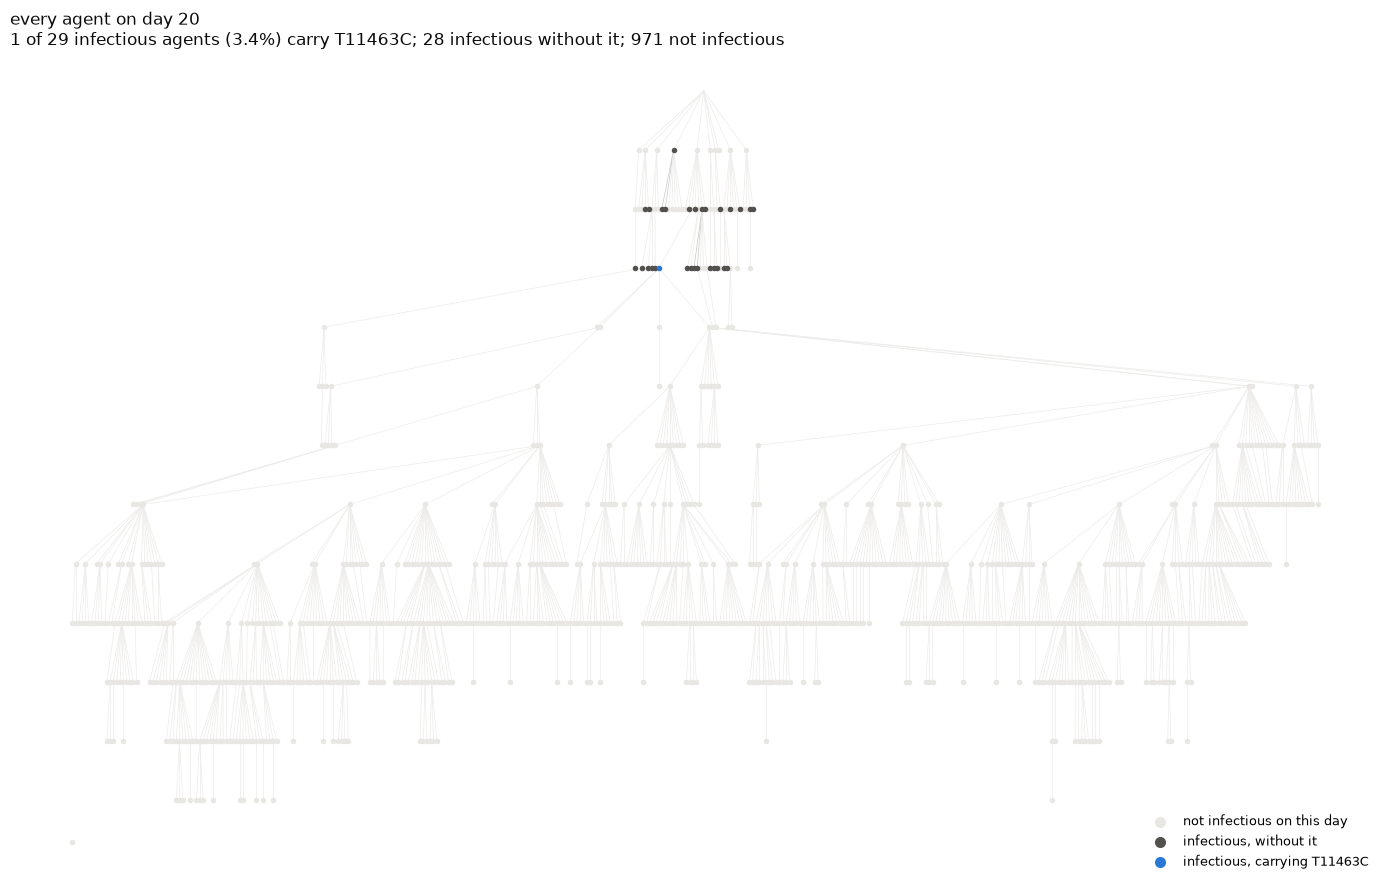

day 20: 1/29 infectious agents carry T11463C = 3.4% prevalence


In [36]:
def build_transmission_tree(sim):
    '''One node per agent, one edge per transmission -- the who-infected-whom tree.

    Unlike the haplotype tree, nothing is collapsed: every infected agent is their own
    node, so counting nodes counts people. Seeds hang off a virtual "root".

    Args:
        sim (Sim): the finished sim

    Returns:
        DiGraph with int agent ids as nodes, plus the string "root"
    '''
    T = nx.DiGraph()
    T.add_node("root")
    for entry in sim.people.infection_log:
        target = int(entry["target"])
        T.add_node(target, day=entry["date"])
        T.add_edge("root" if entry["source"] is None else int(entry["source"]), target)
    return T


def agent_carries(sim, mutation):
    '''Set of agents whose genome carries this mutation, read from the infection log.'''
    carried = agent_mutations_from_log(sim)
    out = set()
    for agent, mutations in carried.items():
        if any(mutation_label(*m) == mutation for m in mutations):
            out.add(int(agent))
    return out


def plot_agents_on_day(sim, day, mutation, T=None, pos=None, ax=None, uninfected=True,
                       pool='infectious'):
    '''Transmission tree on one day, one dot per agent, coloured by what they carry.

    Prevalence is the share of the pool that carries the mutation: blue dots divided by
    blue + dark grey dots. Agents not in the pool that day are drawn pale for context only;
    they are not in the denominator. Agents never infected have no place in a transmission
    tree, so they are parked in a block underneath.

    Args:
        sim (Sim):          the finished sim
        day (int):          the day to slice on
        mutation (str):     the mutation to colour for
        T (DiGraph):        transmission tree; built if None
        pos (dict):         precomputed layout; pass the same one across days
        ax (axes):          existing axes; a new figure is made if None
        uninfected (bool):  draw the never-infected block
        pool (str):         'infectious' (default) or 'infected', passed to infectious_on_day()

    Returns:
        (ax, info) with the counts behind the subtitle
    '''
    if T is None:
        T = build_transmission_tree(sim)
    if pos is None:
        pos = graphviz_layout(T, prog="dot")
    if ax is None:
        _, ax = plt.subplots(figsize=(14, 9))

    in_pool  = infectious_on_day(sim, day, pool=pool)
    carriers = agent_carries(sim, mutation)
    n_pop    = len(sim.people)

    blue = [a for a in T.nodes if a != "root" and a in in_pool and a in carriers]
    grey = [a for a in T.nodes if a != "root" and a in in_pool and a not in carriers]
    pale = [a for a in T.nodes if a != "root" and a not in in_pool]

    for u, v in T.edges:
        if u in pos and v in pos:
            live = u in in_pool and v in in_pool
            ax.plot(*zip(pos[u], pos[v]), color="#c9c8c5" if live else "#edecea",
                    lw=0.5, zorder=1)

    for nodes, color, z, lab in [(pale, "#e8e7e4", 2, f"not {pool} on this day"),
                                 (grey, "#52514e", 3, f"{pool}, without it"),
                                 (blue, "#2a78d6", 4, f"{pool}, carrying {mutation}")]:
        if nodes:
            ax.scatter([pos[n][0] for n in nodes], [pos[n][1] for n in nodes],
                       s=16, color=color, zorder=z, linewidths=0, label=lab)

    # Never infected: no place in a transmission tree, so block them in underneath
    n_never = n_pop - (T.number_of_nodes() - 1)
    if uninfected and n_never > 0:
        xs = [p[0] for p in pos.values()]
        ys = [p[1] for p in pos.values()]
        x0, x1 = min(xs), max(xs)
        per_row = max(1, int(np.ceil(np.sqrt(n_never * (x1 - x0) / max(1, (max(ys) - min(ys)) * 0.25)))))
        step    = (x1 - x0) / max(1, per_row - 1) if per_row > 1 else 0
        gap     = (max(ys) - min(ys)) * 0.06
        gx = [x0 + (i % per_row) * step for i in range(n_never)]
        gy = [min(ys) - gap - (i // per_row) * gap * 0.55 for i in range(n_never)]
        ax.scatter(gx, gy, s=16, color="#e8e7e4", zorder=2, linewidths=0)

    n_in_pool = len(blue) + len(grey)
    info = dict(day=day, pop=n_pop, pool=pool, pool_size=n_in_pool, carrying=len(blue),
                without=len(grey), not_in_pool=len(pale) + n_never, never_infected=n_never,
                prevalence=len(blue) / n_in_pool if n_in_pool else float("nan"))
    ax.set_title(
        f"every agent on day {day}\n"
        f"{len(blue)} of {n_in_pool} {pool} agents ({info['prevalence']:.1%}) carry {mutation}; "
        f"{len(grey)} {pool} without it; {info['not_in_pool']} not {pool}",
        fontsize=12, color="#0b0b0b", loc="left")
    ax.legend(frameon=False, loc="lower right", fontsize=9, markerscale=2)
    ax.axis("off")
    return ax, info


# Prevalence = blue / (blue + dark grey) dots: the share of the infectious pool carrying it.
# Laying out ~1000 nodes takes a moment; keep T and agent_pos to reuse across days.
T         = build_transmission_tree(sim)
agent_pos = graphviz_layout(T, prog="dot")
# DAY       = int(series.idxmax())
DAY = 20

ax, info = plot_agents_on_day(sim, DAY, "T11463C", T=T, pos=agent_pos)
plt.tight_layout()
plt.show()

print(f"day {DAY}: {info['carrying']}/{info['pool_size']} {info['pool']} agents carry T11463C "
      f"= {info['prevalence']:.1%} prevalence")

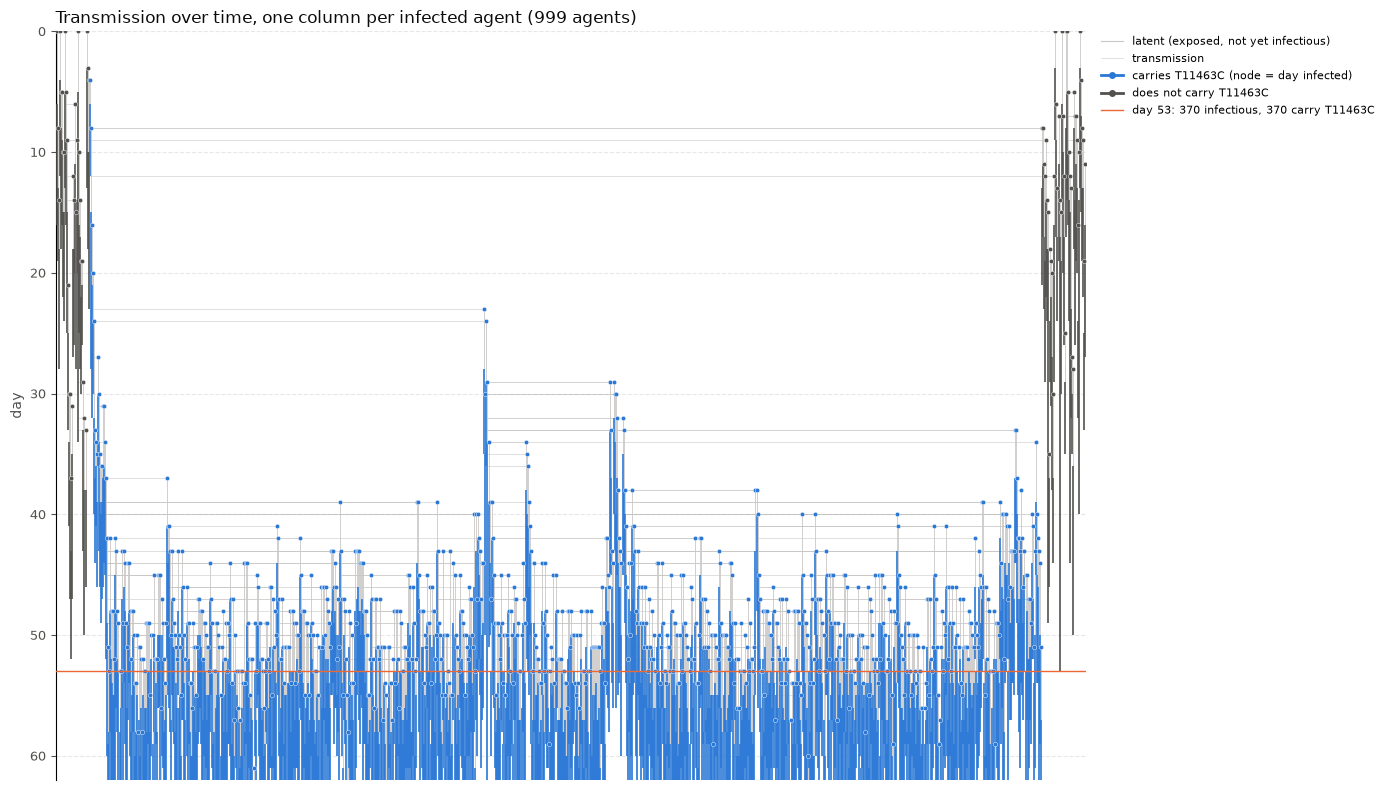

In [15]:
from matplotlib.collections import LineCollection


def transmission_order(T):
    '''Left-to-right order of agents so every transmission chain is a contiguous block.

    Depth-first from the root, children in order of infection day, so each agent sits just
    left of everyone they infected.

    Args:
        T (DiGraph): transmission tree from build_transmission_tree()

    Returns:
        dict agent -> x position (0, 1, 2, ...)
    '''
    order = {}
    stack = ["root"]
    while stack:
        node = stack.pop()
        if node != "root":
            order[node] = len(order)
        children = sorted(T.successors(node), key=lambda n: T.nodes[n].get("day", 0))
        stack.extend(reversed(children))   # reversed so the earliest child is popped first
    return order


def plot_transmission_by_day(sim, mutation=None, T=None, pool='infectious', day=None, ax=None):
    '''Transmission tree with time running down the page: each row is a day.

    Each agent is a node at the day they were infected, coloured by whether they carry the
    mutation, with a vertical bar below it: thin and pale while latent (exposed, not yet
    infectious), thick while in the infectious pool. A horizontal tick marks each transmission, drawn on
    the day it happened, from the source's bar to the new case. A horizontal slice through
    the plot on day d therefore crosses exactly the thick bars of the infectious pool on day d.

    Args:
        sim (Sim):       the finished sim
        mutation (str):  colour nodes and bars by whether the agent carries this mutation;
                         None = one colour
        T (DiGraph):     transmission tree; built if None
        pool (str):      'infectious' (default) or 'infected', passed to infection_windows()
        day (int):       mark this day with a horizontal line and report its pool
        ax (axes):       existing axes; a new figure is made if None

    Returns:
        ax
    '''
    if T is None:
        T = build_transmission_tree(sim)
    if ax is None:
        _, ax = plt.subplots(figsize=(14, 8))

    n_days       = sim['n_days']
    x            = transmission_order(T)
    exposed      = np.asarray(sim.people.date_exposed, dtype=float)
    start, end   = infection_windows(sim, pool=pool)
    end          = np.minimum(end, n_days + 1)          # still infectious at the end -> run off the bottom
    carriers     = agent_carries(sim, mutation) if mutation else set()

    latent, live_with, live_without, links = [], [], [], []
    node_with, node_without = [], []   # (x, day infected) per agent
    for agent, xi in x.items():
        e, s, f = exposed[agent], start[agent], end[agent]
        if np.isfinite(s) and s > e:
            latent.append([(xi, e), (xi, s)])
        bar = [(xi, s), (xi, f)]
        (live_with if agent in carriers else live_without).append(bar)
        (node_with if agent in carriers else node_without).append((xi, e))
        source = next(iter(T.predecessors(agent)), "root")
        if source != "root":
            links.append([(x[source], e), (xi, e)])

    ax.add_collection(LineCollection(links, colors="#c9c8c5", linewidths=0.4, zorder=1))
    ax.add_collection(LineCollection(latent, colors="#c9c8c5", linewidths=0.6, zorder=2))
    ax.add_collection(LineCollection(live_without, colors="#52514e", linewidths=1.2, zorder=3))
    ax.add_collection(LineCollection(live_with, colors="#2a78d6", linewidths=1.2, zorder=4))

    # Nodes: one per agent, at the day they were infected, coloured by the mutation
    for nodes, color, z in [(node_without, "#52514e", 5), (node_with, "#2a78d6", 6)]:
        if nodes:
            ax.scatter(*zip(*nodes), s=10, color=color, edgecolor="white", linewidths=0.3,
                       zorder=z)

    # Legend from proxies, since LineCollections do not label themselves
    handles = [plt.Line2D([], [], color="#c9c8c5", lw=0.8, label="latent (exposed, not yet infectious)"),
               plt.Line2D([], [], color="#c9c8c5", lw=0.4, label="transmission")]
    if mutation:
        handles += [plt.Line2D([], [], color="#2a78d6", lw=2, marker="o", markersize=4,
                               label=f"carries {mutation} (node = day infected)"),
                    plt.Line2D([], [], color="#52514e", lw=2, marker="o", markersize=4,
                               label=f"does not carry {mutation}")]
    else:
        handles += [plt.Line2D([], [], color="#52514e", lw=2, marker="o", markersize=4,
                               label=f"{pool} (node = day infected)")]

    title = f"Transmission over time, one column per infected agent ({len(x)} agents)"
    if day is not None:
        in_pool = infectious_on_day(sim, day, pool=pool)
        n_with  = len(in_pool & carriers)
        ax.axhline(day, color="#eb6834", lw=1.0, zorder=7)
        handles.append(plt.Line2D([], [], color="#eb6834", lw=1.0,
                                  label=f"day {day}: {len(in_pool)} {pool}"
                                        + (f", {n_with} carry {mutation}" if mutation else "")))

    ax.set_xlim(-1, len(x))
    ax.set_ylim(n_days + 1, 0)                          # day 0 at the top
    ax.set_ylabel("day", fontsize=10, color="#52514e")
    ax.set_xticks([])
    ax.yaxis.get_major_locator().set_params(integer=True)
    for side in ["top", "right", "bottom"]:
        ax.spines[side].set_visible(False)
    ax.grid(axis="y", linestyle="--", alpha=0.3)
    ax.tick_params(labelsize=9, colors="#52514e")
    ax.set_title(title, fontsize=12, color="#0b0b0b", loc="left")
    ax.legend(handles=handles, frameon=False, fontsize=8, loc="upper left",
              bbox_to_anchor=(1.01, 1.0), borderaxespad=0)
    return ax


ax = plot_transmission_by_day(sim, mutation="T11463C", T=T, day=DAY)
plt.tight_layout()
plt.show()

simulation without fitness model

In [ ]:
evo_pars = dict(
    enable            = True,
    reference         = REF_FASTA,
    mol_clock_rate    = 1e-5, # ~1 substitution/genome/month at 30 000 nt = 26/29903/12
    sub_model         = 'JC', # decides which mutations happen
    fitness_model = None, # turn this off 
)
sim_pars = dict(
    pop_size=1000,
    pop_type='random',
    pop_infected=10,
    start_day='2021-01-01', 
    n_days=91,
    rand_seed=42,
    verbose=0,    
    variants=[], 
    beta=0.016,
    analyzers=[cs_routine],    
    viral_dist   = dict(
        frac_time=0.3, # is this really 1 in calculation???
        load_ratio=1, # how much more infectious the early phase is than the late phase, flat 
        high_cap=4
    ), 
    beta_dist = dict(dist='neg_binomial', par1=1.0, par2=10000, step=0.01),
    asymp_factor = 1.0, # all infectious agents transmit equally
    iso_factor   = dict(a=1.0), # isolated or quarantined agents are treated the same as everyone, does not affect sim here since no isolation or qurantine in infectious pool
    quar_factor  = dict(a=1.0),
    # rel_symp_prob   = 0.0, # everyone asymptomatic. status of disease: asymptomatic or mild (about 8 days), severe (18+ days), or death
    # rel_severe_prob = 0.0, # no one becomes severe, and therefore no one becomes critical or dies
    use_waning      = False, # true gives recovered agents partial immunity
    trans_redux     = 1.0, # Breakthrough reduction: on a first breakthrough infection, rel_trans is multiplied by trans_redux
)


sim = cv.Sim(pars=sim_pars, evo_pars=evo_pars)
sim.initialize()
sim.people.rel_trans[:] = 1.0 # how infectious this agent is when they are infected
sim.people.rel_sus[:]   = 1.0 # how easily this agent will be infected
sim.run()

cs_routine = sim.get_analyzer('CS_routine')

In [ ]:
G = build_mutation_tree(sim) # event-base tt
print(f"Policy B mutation tree: nodes={len(G.nodes)}, edges={len(G.edges)}")

H, mutation_nodes, node_events = build_infection_seq_tree(sim) # halpotype-based
plot_mutation_tree(H, title="Ground-Truth Haplotype Tree")

In [ ]:
plot_rt(sim)

In [ ]:
node_stats = compute_node_stats(H, mutation_nodes, node_events)
plot_ndesc_vs_fitness(node_stats)